## Literature Review Summary — Breast Cancer Papers

| # | Paper (Citation) | Key Findings | Relevance to EDA | Relevance to ML |
|---|---|---|---|---|
| 1 | **Obeagu & Obeagu (2024)** — *Breast cancer: A review of risk factors and diagnosis*, Medicine | Major risk factors: age (50–69 yrs most common), family history, BRCA1/2 mutations (85% lifetime risk if inherited), dense breast tissue, late menopause (>55), late/no pregnancy, HRT use, obesity (BMI>31 → 2.5x risk), estrogen exposure | Confirms age, BMI, menopause status, family history, hormone exposure as important features to explore for distribution/skew and correlation with malignancy | Strong candidate engineered features/categorical risk flags; useful for feature importance validation and clinical plausibility checks |
| 2 | **Xiong et al. (2025)** — *Breast cancer: pathogenesis and treatments*, Signal Transduction and Targeted Therapy | Detailed molecular subtypes (Luminal A/B, HER2-enriched, TNBC) based on ER/PR/HER2/Ki67; genetic drivers (BRCA1/2, TP53, PIK3CA); AI/deep learning improves diagnostic accuracy (up to 37.3% fewer false positives); ctDNA sensitivity ~70–90%, specificity ~88–90% | Check if dataset has ER/PR/HER2/Ki67 columns — these drive subtype labels, useful for creating a target/subgroup variable; explore class imbalance across subtypes | Supports using CNNs for image-based diagnosis, tree-based/ensemble models for tabular biomarker data; benchmark model against reported AI sensitivity/specificity (~80–90%) |
| 3 | **Łukasiewicz et al. (2021)** — *Breast Cancer — Epidemiology, Risk Factors, Classification, Prognostic Markers*, Cancers (MDPI) | Comprehensive table of modifiable/non-modifiable risk factors; prognostic biomarkers: ER, PR, HER2, Ki-67, E-cadherin, p53, miRNAs, TAMs, NLR/LMR/PLR (inflammation ratios); AJCC 8th edition staging combines anatomy + biology | Excellent reference for feature list & correlation hypotheses (e.g., higher Ki-67 → poorer prognosis, high NLR → worse survival) — good for correlation heatmaps and hypothesis-driven EDA | NLR/LMR/PLR are derived ratio features worth engineering if raw blood count data available; Ki-67, ER/PR/HER2 status are strong predictive features for classification models |

## Feature Availability Check — Literature vs. Dataset

| Literature-Suggested Feature | Source Paper(s) | In Dataset? | Matching Column(s) | Notes |
|---|---|---|---|---|
| Age | Obeagu & Obeagu (2024) | Yes | `age` | Bin into risk brackets (<50, 50–69, >69) |
| Family history | Obeagu & Obeagu (2024) | Yes | `family_history` | Direct match |
| Menopausal status | Obeagu & Obeagu (2024) | Yes | `menopausal_status` | Supports late-menopause risk hypothesis |
| BRCA1/BRCA2 mutation status | Obeagu & Obeagu (2024); Xiong et al. (2025) | No | — | `family_history` only a weak proxy |
| BMI / Obesity | Obeagu & Obeagu (2024) | No | — | Can't test BMI>31 → 2.5x risk claim |
| Late/no pregnancy, HRT, estrogen exposure | Obeagu & Obeagu (2024) | No | — | Not collected |
| ER / PR / HER2 status | Xiong et al. (2025); Łukasiewicz et al. (2021) | No | — | Molecular subtyping not possible |
| Ki-67 index | Xiong et al. (2025); Łukasiewicz et al. (2021) | No | — | Can't test Ki-67 → prognosis link |
| TP53, PIK3CA drivers | Xiong et al. (2025) | No | — | No genomic data |
| NLR / LMR / PLR | Łukasiewicz et al. (2021) | No | — | No raw blood counts to derive these |
| E-cadherin, p53, miRNAs, TAMs | Łukasiewicz et al. (2021) | No | — | Not present |
| Tumor size / morphology | All 3 papers | Yes | `mean_radius`, `mean_perimeter`, `mean_area`, `worst_radius`, `worst_perimeter`, `worst_area` | Core strength of dataset |
| Texture / shape irregularity | Łukasiewicz et al. (2021) | Yes | `mean_texture`, `mean_smoothness`, `mean_compactness`, `mean_concavity`, `mean_concave_points`, `mean_symmetry`, `mean_fractal_dimension` + `worst_*` | Concavity/concave points historically strong predictors |
| AJCC staging (anatomy + biology) | Łukasiewicz et al. (2021) | Partial | `pathology_final`, `treatment_recommendation` | May encode staging indirectly, not explicit stage |
| Unlabeled columns | — | N/A | `marker_x`, `random_noise_feature` | Verify origin; noise column likely a feature-importance sanity check |

## Target Variable Candidates vs. Literature-Supported Tasks

| Column | Literature-Supported Task | Supporting Paper(s) | Feasibility |
|---|---|---|---|
| `diagnosis` | Binary malignant vs. benign | Obeagu & Obeagu (2024); Łukasiewicz et al. (2021) | Fully supported |
| `pathology_final` | Confirmed/biopsy-level label | Łukasiewicz et al. (2021) | Supported; check redundancy with `diagnosis` |
| `treatment_recommendation` | Clinical decision support | Not directly covered by these 3 papers | Different problem — likely multi-class, imbalanced |
| Molecular subtype (Luminal A/B, HER2-enriched, TNBC) | Subtype classification | Xiong et al. (2025) | Not feasible — needs ER/PR/HER2/Ki-67 |

## Feature Engineering Ideas — Adapted to Dataset

| Original Idea | Source | Blocked By | Adapted Version |
|---|---|---|---|
| NLR, LMR, PLR ratios | Łukasiewicz et al. (2021) | No blood count columns | Not feasible — drop |
| BRCA + family history + age risk score | Obeagu & Obeagu (2024) | No genetic column | `age` × `family_history` × `menopausal_status` interaction flag |
| ER/PR/HER2/Ki-67 irregularity score | Łukasiewicz et al. (2021); Xiong et al. (2025) | No biomarker columns | Composite score from `mean_concavity`, `mean_concave_points`, `mean_compactness` |
| — | — | — | New: mean-to-worst ratios, e.g. `worst_radius/mean_radius`, `worst_concavity/mean_concavity` (tumor heterogeneity proxy) |

## Benchmarking Reference

| Metric | Reported Value | Source |
|---|---|---|
| AI diagnostic sensitivity/specificity | ~80–90% | Xiong et al. (2025) |
| AI reduction in false positives | Up to 37.3% fewer | Xiong et al. (2025) |
| ctDNA sensitivity | ~70–90% | Xiong et al. (2025) |
| ctDNA specificity | ~88–90% | Xiong et al. (2025) |

# Breast Cancer Classification — Data Cleaning, Preprocessing & Logistic Regression

This notebook continues from the EDA stage and builds a complete, leakage-aware logistic-regression workflow.

## Learning flow

**Raw data → Cleaning → Train/Test Split → Preprocessing → Logistic Regression → Probability → Threshold → Class → Evaluation → Odds Ratios**

The notebook is designed for classroom use. Each major step includes a short interpretation prompt.

In [1]:
# 1. Import libraries

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    roc_curve,
    roc_auc_score
)

DATA_PATH = r"/mnt/data/synthetic_messy_breast_cancer_eda_ml_dataset(1).xlsx"
print("Using dataset:", DATA_PATH)

/home/oai/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-r4ihjljp because there was an issue with the default path (/home/oai/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Using dataset: /mnt/data/synthetic_messy_breast_cancer_eda_ml_dataset(1).xlsx


In [2]:
# 2. Load the dataset

df = pd.read_excel(DATA_PATH)

print("Shape:", df.shape)
display(df.head())

Shape: (1200, 29)


,patient_id,age,family_history,menopausal_status,mean_radius,mean_texture,mean_perimeter,mean_area,mean_smoothness,mean_compactness,mean_concavity,mean_concave_points,mean_symmetry,mean_fractal_dimension,worst_radius,worst_texture,worst_perimeter,worst_area,worst_smoothness,worst_compactness,worst_concavity,worst_concave_points,worst_symmetry,worst_fractal_dimension,marker_x,random_noise_feature,pathology_final,treatment_recommendation,diagnosis
0,BC00461,45.0,Yes,Pre,11.37,10.736,71.122,349.37,0.12605,0.11051,0,0.04278,0.18734,0.05925,13.489,13.808,93.939,394.15,0.18795,0.14422,0.00000,0.05545,0.24417,0.07643,21.841,0.75857,Negative,6-month imaging,Benign
1,BC00920,58.0,No,Post,22.295,32.116,133.338,1334.75,0.11045,0.13459,NaN,0.06550,0.22138,0.04911,24.687,36.079,166.689,2397.68,0.12110,0.22219,0.22255,0.09130,0.26404,0.05772,23.99,0.56270,Positive,Surgery,Malignant
2,BC01125,30.0,No,Pre,13.743,21.371,89.666,568.73,NaN,0.05624,0.0618,0.04288,0.21173,0.05366,16.210,27.603,103.915,662.17,0.16451,0.07747,0.07489,0.05473,0.27999,0.07496,12.469,0.75774,Negative,Routine follow-up,Benign
3,BC00074,50.0,No,Post,14.928,16.07,94.466,595.74,0.11143,0.07854,0.00787,0.06765,0.18613,0.06529,15.557,20.298,112.791,856.34,0.13493,0.08018,0.01007,0.07257,0.22380,0.09471,NaN,0.55866,Negative,6-month imaging,Benign
4,BC00259,46.0,No,POST,NaN,18.188,118.294,925.68,0.07917,0.05265,0.04928,0.02334,0.18460,0.06185,20.329,24.483,139.204,1238.96,0.10345,0.06774,0.06075,0.02352,0.25276,0.07366,21.413,0.31574,Negative,Routine follow-up,Benign


## 3. Keep a raw copy

Never overwrite the original dataset during cleaning. This lets us compare raw and cleaned versions.

In [3]:
raw_df = df.copy()
clean_df = df.copy()

# Part A — Data Cleaning

In [4]:
# 4. Standardize column names

clean_df.columns = (
    clean_df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

print(clean_df.columns.tolist())

['patient_id', 'age', 'family_history', 'menopausal_status', 'mean_radius', 'mean_texture', 'mean_perimeter', 'mean_area', 'mean_smoothness', 'mean_compactness', 'mean_concavity', 'mean_concave_points', 'mean_symmetry', 'mean_fractal_dimension', 'worst_radius', 'worst_texture', 'worst_perimeter', 'worst_area', 'worst_smoothness', 'worst_compactness', 'worst_concavity', 'worst_concave_points', 'worst_symmetry', 'worst_fractal_dimension', 'marker_x', 'random_noise_feature', 'pathology_final', 'treatment_recommendation', 'diagnosis']


In [5]:
# 5. Inspect object/category columns before cleaning

object_cols = clean_df.select_dtypes(include="object").columns

for col in object_cols:
    print(f"\n--- {col} ---")
    print(clean_df[col].astype(str).value_counts(dropna=False).head(15))


--- patient_id ---
patient_id
BC01013    2
BC00147    2
BC00171    2
BC01061    2
BC00263    2
BC00241    2
BC00713    2
BC00570    2
BC00895    2
BC00154    2
BC01036    2
BC01029    2
BC00878    2
BC00670    2
BC00301    2
Name: count, dtype: int64

--- family_history ---
family_history
No       896
Yes      221
nan       28
YES        9
Y          8
 No        8
N          7
no         7
yes        6
 Yes       5
NO         5
Name: count, dtype: int64

--- menopausal_status ---
menopausal_status
Pre               578
Post              554
nan                24
post               12
POST               10
PRE                 8
Post-menopause      7
Pre-menopause       4
pre                 3
Name: count, dtype: int64

--- mean_radius ---
mean_radius
nan       60
12.778     3
14.688     3
14.131     2
10.031     2
13.809     2
11.149     2
19.105     2
13.728     2
13.329     2
8.207      2
13.847     2
13.149     2
12.483     2
14.357     2
Name: count, dtype: int64

--- mean_texture

### Why this matters

Messy datasets often contain labels such as `Yes`, `YES`, `yes`, or `Y`.  
To a machine-learning model, these can appear to be different categories unless we standardize them.

In [6]:
# 6. Generic text cleaning

for col in clean_df.select_dtypes(include="object").columns:
    clean_df[col] = clean_df[col].apply(
        lambda x: x.strip() if isinstance(x, str) else x
    )

# Standardize diagnosis explicitly
if "diagnosis" in clean_df.columns:
    diagnosis_map = {
        "benign": "Benign",
        "b": "Benign",  
        "malignant": "Malignant",
        "m": "Malignant"
    }

    clean_df["diagnosis"] = clean_df["diagnosis"].apply(
        lambda x: diagnosis_map.get(x.lower(), x)
        if isinstance(x, str) else x
    )

print(clean_df["diagnosis"].value_counts(dropna=False))

diagnosis
Benign       835
Malignant    365
Name: count, dtype: int64


In [7]:
# 7. Standardize common yes/no spellings

yes_values = {"yes", "y", "true", "1"}
no_values  = {"no", "n", "false", "0"}

for col in clean_df.select_dtypes(include="object").columns:
    vals = clean_df[col].dropna().apply(
        lambda x: x.lower() if isinstance(x, str) else x
    )
    unique_vals = set(vals.unique())

    if unique_vals and unique_vals.issubset(yes_values | no_values):
        clean_df[col] = clean_df[col].apply(
            lambda x: (
                "Yes" if isinstance(x, str) and x.lower() in yes_values
                else "No" if isinstance(x, str) and x.lower() in no_values
                else np.nan if pd.isna(x)
                else x
            )
        )

print("Yes/No standardization completed.")

Yes/No standardization completed.


In [8]:
# 8. Remove exact duplicate rows

before = len(clean_df)
clean_df = clean_df.drop_duplicates().copy()
after = len(clean_df)

print("Rows before:", before)
print("Rows after :", after)
print("Exact duplicates removed:", before - after)

Rows before: 1200
Rows after : 1187
Exact duplicates removed: 13


### Duplicate patient IDs

A repeated patient ID does **not automatically mean** the row is a duplicate.  
It may represent repeated measurements. We inspect them rather than blindly deleting them.

In [9]:
# 9. Inspect duplicate patient IDs

if "patient_id" in clean_df.columns:
    duplicate_id_mask = clean_df["patient_id"].duplicated(keep=False)
    duplicate_ids = clean_df.loc[duplicate_id_mask].sort_values("patient_id")
    print("Rows with duplicated patient IDs:", len(duplicate_ids))
    display(duplicate_ids.head(20))

Rows with duplicated patient IDs: 14


,patient_id,age,family_history,menopausal_status,mean_radius,mean_texture,mean_perimeter,mean_area,mean_smoothness,mean_compactness,mean_concavity,mean_concave_points,mean_symmetry,mean_fractal_dimension,worst_radius,worst_texture,worst_perimeter,worst_area,worst_smoothness,worst_compactness,worst_concavity,worst_concave_points,worst_symmetry,worst_fractal_dimension,marker_x,random_noise_feature,pathology_final,treatment_recommendation,diagnosis
82,BC00147,52.0,No,Post,13.014,19.771,77.623,414.48,0.10354,0.11214,0.05321,0.05263,0.16356,0.05765,12.135,21.61,78.476,537.77,0.13933,0.20396,0.07846,0.08019,0.24277,0.07640,32.344,0.73349,Negative,Routine follow-up,Benign
1040,BC00147,52.0,No,Post,13.014,20.383,77.623,414.48,0.10354,0.11214,0.05321,0.05263,0.16356,0.05765,12.135,21.61,78.476,537.77,0.13933,0.20396,0.07846,0.08019,0.24277,0.07640,32.344,0.73349,Negative,Routine follow-up,Benign
929,BC00154,62.0,No,Post,17.603,22.265,112.739,804.26,0.10806,NaN,0.10205,0.08217,0.19197,0.05899,23.083,25.901,144.840,1290.53,0.15645,0.18277,0.19103,0.12130,0.22360,0.08150,23.544,0.06591,Positive,Surgery,Malignant
1084,BC00154,62.0,No,Post,17.603,22.218,112.739,804.26,0.10806,NaN,0.10205,0.08217,0.19197,0.05899,23.083,25.901,144.840,1290.53,0.15645,0.18277,0.19103,0.12130,0.22360,0.08150,23.544,0.06591,Positive,Surgery,Malignant
111,BC00171,70.0,Yes,Post,14.205,21.446,89.318,535.72,0.11639,0.0821,0.11094,0.14461,0.21015,0.07273,16.838,24.91,91.122,1070.92,0.15996,0.12223,0.20256,0.17190,0.33899,0.10784,46.649,0.11269,Positive,Surgery,Malignant
810,BC00171,70.0,Yes,Post,14.205,21.529,89.318,535.72,0.11639,0.0821,0.11094,0.14461,0.21015,0.07273,16.838,24.91,91.122,1070.92,0.15996,0.12223,0.20256,0.17190,0.33899,0.10784,46.649,0.11269,Positive,Surgery,Malignant
169,BC00241,56.0,No,Post,NaN,26.278,89.260,575.89,0.11328,0.04082,0,0.01994,0.17660,0.05305,16.394,38.937,101.769,1003.35,0.13789,0.04752,0.00000,0.02825,0.26012,0.06961,22.747,0.09856,Negative,6-month imaging,Benign
475,BC00241,56.0,No,Post,NaN,26.574,89.260,575.89,0.11328,0.04082,0,0.01994,0.17660,0.05305,16.394,38.937,101.769,1003.35,0.13789,0.04752,0.00000,0.02825,0.26012,0.06961,22.747,0.09856,Negative,6-month imaging,Benign
988,BC00680,38.0,No,Pre,17.82,20.025,114.520,849.32,0.10849,0.18929,0.21991,0.09491,0.23885,0.05237,23.143,25.956,149.677,1269.72,0.16056,0.29407,0.34939,0.14272,0.29533,0.06998,28.32,0.82956,Positive,Oncology referral,Malignant
1054,BC00680,38.0,No,Pre,17.82,20.106,114.520,849.32,0.10849,0.18929,0.21991,0.09491,0.23885,0.05237,23.143,25.956,149.677,1269.72,0.16056,0.29407,0.34939,0.14272,0.29533,0.06998,28.32,0.82956,Positive,Oncology referral,Malignant


In [10]:
# 10. Detect impossible ages

if "age" in clean_df.columns:
    clean_df["age"] = pd.to_numeric(clean_df["age"], errors="coerce")

    impossible_age = (clean_df["age"] < 18) | (clean_df["age"] > 100)
    print("Impossible age values:", impossible_age.sum())
    display(clean_df.loc[impossible_age, ["age", "diagnosis"]].head(20))

    # Treat impossible values as missing rather than inventing replacements
    clean_df.loc[impossible_age, "age"] = np.nan

Impossible age values: 10


,age,diagnosis
56,145.0,Benign
104,145.0,Benign
167,7.0,Benign
304,145.0,Benign
821,7.0,Benign
907,120.0,Benign
923,7.0,Benign
949,120.0,Malignant
1134,-4.0,Benign
1188,-4.0,Benign


### Important modelling principle

We do **not** fill missing values using the whole dataset before the train/test split.  
Doing that would let information from the test set influence the training process.

Instead, imputation will be fitted **inside a preprocessing pipeline using training data only**.

In [11]:
# 11. Convert mostly-numeric object columns to numeric where appropriate

for col in clean_df.columns:
    if clean_df[col].dtype == "object" or str(clean_df[col].dtype).startswith("string"):
        converted = pd.to_numeric(clean_df[col], errors="coerce")
        original_non_missing = clean_df[col].notna().sum()
        converted_non_missing = converted.notna().sum()

        if original_non_missing > 0 and converted_non_missing / original_non_missing >= 0.80:
            clean_df[col] = converted
            print("Converted to numeric:", col)

Converted to numeric: mean_radius
Converted to numeric: mean_texture
Converted to numeric: mean_area
Converted to numeric: mean_compactness
Converted to numeric: mean_concavity
Converted to numeric: worst_texture
Converted to numeric: marker_x


In [12]:
# 12. Missing values after cleaning

missing = (
    clean_df.isna().sum()
    .to_frame("missing_count")
    .assign(missing_percent=lambda x: 100 * x["missing_count"] / len(clean_df))
    .sort_values("missing_percent", ascending=False)
)

display(missing[missing["missing_count"] > 0])

,missing_count,missing_percent
mean_concavity,117,9.856782
marker_x,106,8.930076
mean_compactness,99,8.340354
mean_texture,85,7.160910
worst_compactness,71,5.981466
worst_texture,68,5.728728
mean_area,64,5.391744
mean_radius,61,5.139006
worst_radius,53,4.465038
mean_concave_points,51,4.296546


# Part B — Define the Modelling Problem

We want to predict **diagnosis**.

- `Malignant = 1`
- `Benign = 0`

In [13]:
# 13. Create binary target

clean_df = clean_df[clean_df["diagnosis"].isin(["Benign", "Malignant"])].copy()

clean_df["target"] = clean_df["diagnosis"].map({
    "Benign": 0,
    "Malignant": 1
})

print(clean_df[["diagnosis", "target"]].value_counts())

diagnosis  target
Benign     0         825
Malignant  1         362
Name: count, dtype: int64


## 14. Remove identifiers and leakage variables

`patient_id` is an identifier, not a biological predictor.

Variables such as `pathology_final` or `treatment_recommendation` may contain information produced **after diagnosis**. Using them to predict diagnosis would create **target leakage**.

In [14]:
# 14. Define columns to exclude

possible_leakage = [
    "pathology_final",
    "treatment_recommendation"
]

identifier_cols = [
    "patient_id"
]

target_cols = [
    "diagnosis",
    "target"
]

drop_cols = [
    col for col in possible_leakage + identifier_cols + target_cols
    if col in clean_df.columns
]

X = clean_df.drop(columns=drop_cols)
y = clean_df["target"]

print("Excluded columns:", drop_cols)
print("Predictor matrix shape:", X.shape)

Excluded columns: ['pathology_final', 'treatment_recommendation', 'patient_id', 'diagnosis', 'target']
Predictor matrix shape: (1187, 25)


In [15]:
# 15. Remove columns with no usable variation

constant_or_empty = [
    col for col in X.columns
    if X[col].nunique(dropna=True) <= 1   # nan count mat karo
]

print("Constant/empty columns removed:", constant_or_empty)
X = X.drop(columns=constant_or_empty)

Constant/empty columns removed: []


# Part C — Train/Test Split

The split occurs **before imputation, scaling, and one-hot encoding**.

This protects the test set from leakage.

In [16]:
# 16. Stratified train/test split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y        # helps maintain the class balance
)

print("Training rows:", len(X_train))
print("Testing rows :", len(X_test))

print("\nTraining target proportion:")
print(y_train.value_counts(normalize=True))

print("\nTesting target proportion:")
print(y_test.value_counts(normalize=True))

Training rows: 949
Testing rows : 238

Training target proportion:
target
0    0.695469
1    0.304531
Name: proportion, dtype: float64

Testing target proportion:
target
0    0.693277
1    0.306723
Name: proportion, dtype: float64


# Part D — Preprocessing Pipeline

Numerical variables:
- median imputation
- standardization

Categorical variables:
- most-frequent imputation
- one-hot encoding

In [17]:
# 17. Identify numerical and categorical predictors

numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

print("Numerical features:", len(numeric_features))
print(numeric_features)

print("\nCategorical features:", len(categorical_features))
print(categorical_features)

Numerical features: 23
['age', 'mean_radius', 'mean_texture', 'mean_perimeter', 'mean_area', 'mean_smoothness', 'mean_compactness', 'mean_concavity', 'mean_concave_points', 'mean_symmetry', 'mean_fractal_dimension', 'worst_radius', 'worst_texture', 'worst_perimeter', 'worst_area', 'worst_smoothness', 'worst_compactness', 'worst_concavity', 'worst_concave_points', 'worst_symmetry', 'worst_fractal_dimension', 'marker_x', 'random_noise_feature']

Categorical features: 2
['family_history', 'menopausal_status']


In [18]:
# 18. Build preprocessing pipelines

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", drop="first")) 
])   # Don't crash. Just handle the unknown category safely.
# o drop="first" removes one category to avoid redundant information

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ], 
    remainder="drop"    # If there are any columns that we didn't mention, remove them.
)

print(preprocessor)

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['age', 'mean_radius', 'mean_texture',
                                  'mean_perimeter', 'mean_area',
                                  'mean_smoothness', 'mean_compactness',
                                  'mean_concavity', 'mean_concave_points',
                                  'mean_symmetry', 'mean_fractal_dimension',
                                  'worst_radius', 'worst_texture',
                                  'worst_...rst_area',
                                  'worst_smoothness', 'worst_compactness',
                                  'worst_concavity', 'worst_concave_points',
                                  'worst_symmetry', 'worst_fractal_dimension',
                  

# Part E — Logistic Regression

Remember the conceptual flow:

**X variables → linear score/log-odds → sigmoid → probability → threshold → class**

In [19]:
# 19. Create the complete modelling pipeline

logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=5000,# the maximum number of update attempts Logistic Regression can make to find the best coefficients before it stops training.
        class_weight=None,# Treat both classes normally; don't give either class extra importance.
        random_state=42# you get the same result every time you run the code.
    ))
])

logistic_model.fit(X_train, y_train) # "Take my training data, preprocess it, and teach the Logistic Regression model how to predict the target.

print("Logistic regression fitted successfully.")

Logistic regression fitted successfully.


In [20]:
# 20. Predict probability and class

y_prob = logistic_model.predict_proba(X_test)[:, 1]
# predict_proba() gives two probabilities for each patient. benign and malignant prob...
# [:, 1] means: Take every row (:), but only column 1.how likely is malignant.
y_pred = logistic_model.predict(X_test)
# Final class decision by the model.

prediction_preview = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted_probability_malignant": y_prob,
    "Predicted_class": y_pred
})
  
display(prediction_preview.head(15))

# predict_prob gives probability
# predict() gives the final class.

,Actual,Predicted_probability_malignant,Predicted_class
0,1,0.862335,1
1,1,0.849966,1
2,0,0.001490,0
3,0,0.008521,0
4,0,0.006840,0
5,0,0.076835,0
6,0,0.023153,0
7,0,0.008498,0
8,0,0.037775,0
9,1,0.994938,1


Actual                    → What really happened

Predicted_probability     → Model's probability

Predicted_class           → Model's final decision

## Probability is not the class

`predict_proba()` gives a continuous probability.

The default logistic-regression decision threshold is usually:

\[
p \ge 0.5 \Rightarrow 1
\]

\[
p < 0.5 \Rightarrow 0
\]

In [21]:
# 21. Demonstrate threshold manually

threshold = 0.50
y_pred_manual = (y_prob >= threshold).astype(int)
# Converts probabilities into 0/1 predictions using the 50% threshold.

print("Manual threshold predictions equal sklearn predictions:",
      np.array_equal(y_pred_manual, y_pred))
# Checks whether our manually created predictions match sklearn's predict() results.

Manual threshold predictions equal sklearn predictions: True


# Part F — Confusion Matrix

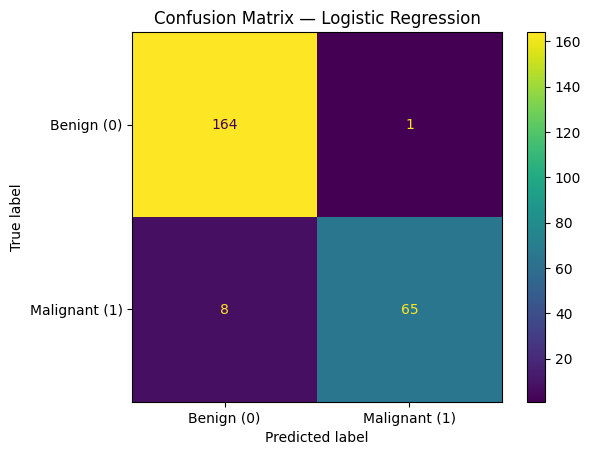

True Negatives : 164
False Positives: 1
False Negatives: 8
True Positives : 65


In [22]:
# 22. Confusion matrix

cm = confusion_matrix(y_test, y_pred)
# Compares the actual classes with the model's predicted classes and counts the correct and incorrect predictions.

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Benign (0)", "Malignant (1)"]
)

disp.plot()
plt.title("Confusion Matrix — Logistic Regression")
plt.show()

tn, fp, fn, tp = cm.ravel()
# ravel() is used to separate the confusion matrix into TN, FP, FN, and TP so we can use them individually.

print("True Negatives :", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives :", tp)

For a cancer-classification problem, **false negatives deserve special attention** because they represent malignant cases predicted as benign.

# Part G — Accuracy, Precision, Recall and F1

In [23]:
# 23. Classification metrics

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

metrics_df = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Value": [accuracy, precision, recall, f1]
})

display(metrics_df)

print(classification_report(
    y_test,
    y_pred,
    target_names=["Benign", "Malignant"]
))

TP → Malignant correctly found
TN → Benign correctly found
FP → Benign wrongly called Malignant
FN → Malignant wrongly called Benign

,Metric,Value
0,Accuracy,0.962185
1,Precision,0.984848
2,Recall,0.890411
3,F1-score,0.935252


              precision    recall  f1-score   support

      Benign       0.95      0.99      0.97       165
   Malignant       0.98      0.89      0.94        73

    accuracy                           0.96       238
   macro avg       0.97      0.94      0.95       238
weighted avg       0.96      0.96      0.96       238



### Interpretation

- **Accuracy**: overall proportion classified correctly.
- **Precision**: among cases predicted malignant, how many were actually malignant?
- **Recall / Sensitivity**: among truly malignant cases, how many did the model detect?
- **F1-score**: harmonic balance between precision and recall.

For medical screening, recall can be more important than accuracy alone.

# Part H — ROC Curve and ROC-AUC

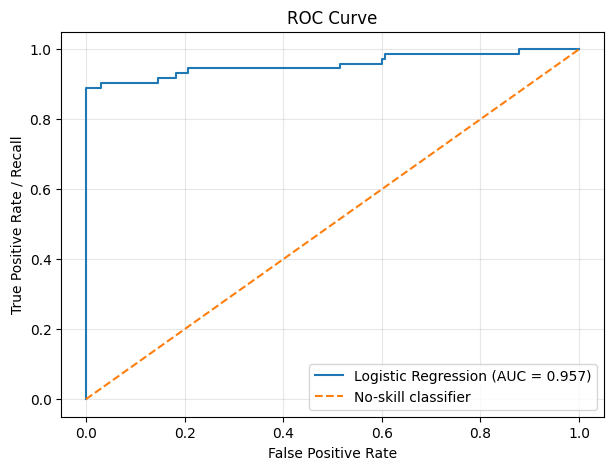

ROC-AUC: 0.9567


In [24]:
# 24. ROC curve and AUC- area under curve, receiver operating characterstics.
auc = roc_auc_score(y_test, y_prob)# AUC tells us how well the model can separate the two classes.
# at differnt thresholds.
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
# true postive rate also called recall
# FALSE POSITIVE rate _Out of all actual Benign patients, how many did the model incorrectly call Malignant?
# ROC is asking, If I change my threshold, how many actual Malignant patients can I catch,
# and how many Benign patients will I wrongly classify as Malignant?
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {auc:.3f})")
# {auc:.3f}: show only 3 digits after the decimal.
plt.plot([0, 1], [0, 1], linestyle="--", label="No-skill classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate / Recall")
plt.title("ROC Curve")
plt.legend()
plt.grid(alpha=0.3) # alpha=0.3 controls how transparent/light the grid is
plt.show()

print("ROC-AUC:", round(auc, 4))

# diagonal line TPR=FPR

ROC-AUC measures the model's ability to rank malignant cases above benign cases **across all possible thresholds**.

- `0.5` ≈ no discrimination
- `1.0` = perfect discrimination

# Part I — Effect of Changing the Threshold

In [25]:
# 25. Compare classification metrics at different thresholds

threshold_results = []

for t in [0.30, 0.40, 0.50, 0.60, 0.70]:# Tests the model at five different thresholds.
    pred_t = (y_prob >= t).astype(int)
    # converts probabilities into final 0/1 predictions using the current threshold.

    threshold_results.append({
        "Threshold": t,
        "Accuracy": accuracy_score(y_test, pred_t),
        "Precision": precision_score(y_test, pred_t, zero_division=0),
        "Recall": recall_score(y_test, pred_t, zero_division=0),
        "F1": f1_score(y_test, pred_t, zero_division=0)
    })

threshold_df = pd.DataFrame(threshold_results)
display(threshold_df)

,Threshold,Accuracy,Precision,Recall,F1
0,0.3,0.957983,0.970149,0.890411,0.928571
1,0.4,0.957983,0.970149,0.890411,0.928571
2,0.5,0.962185,0.984848,0.890411,0.935252
3,0.6,0.962185,1.000000,0.876712,0.934307
4,0.7,0.953782,1.000000,0.849315,0.918519


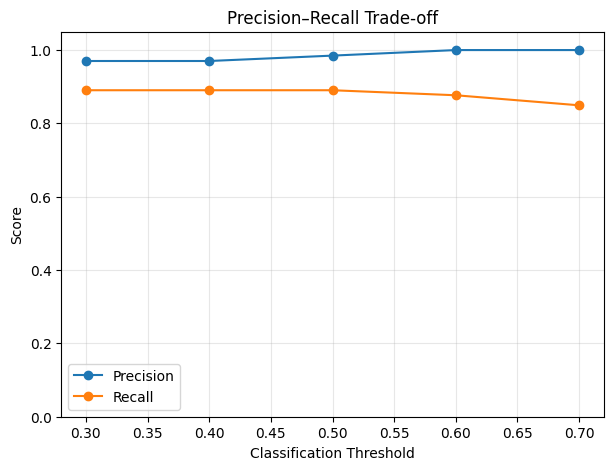

In [26]:
# 26. Plot precision and recall against threshold

plt.figure(figsize=(7, 5))
plt.plot(threshold_df["Threshold"], threshold_df["Precision"], marker="o", label="Precision")
plt.plot(threshold_df["Threshold"], threshold_df["Recall"], marker="o", label="Recall")
plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Precision–Recall Trade-off")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

This demonstrates an important idea:

**Changing the threshold changes the classifier without retraining logistic regression.**

# Part J — Logistic Regression Coefficients and Odds Ratios

A logistic-regression coefficient is expressed in **log-odds units**.

Exponentiating a coefficient converts it to an **odds ratio**:

\[
OR = e^{\beta}
\]

Interpretation:

- `OR > 1`: higher predictor value is associated with higher odds of malignancy.
- `OR < 1`: higher predictor value is associated with lower odds of malignancy.
- `OR = 1`: no change in odds.

In [27]:
# 27. Extract transformed feature names and coefficients

fitted_preprocessor = logistic_model.named_steps["preprocessor"]
classifier = logistic_model.named_steps["classifier"]

feature_names = fitted_preprocessor.get_feature_names_out()
coefficients = classifier.coef_[0]

coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient_log_odds": coefficients,
    "Odds_Ratio": np.exp(coefficients)
})

coef_df["Abs_coefficient"] = coef_df["Coefficient_log_odds"].abs()
coef_df = coef_df.sort_values("Abs_coefficient", ascending=False)

display(coef_df.head(25))

,Feature,Coefficient_log_odds,Odds_Ratio,Abs_coefficient
26,cat__menopausal_status_Post-menopause,1.475287,4.372292,1.475287
3,num__mean_perimeter,-1.112451,0.328752,1.112451
14,num__worst_area,1.104075,3.016432,1.104075
11,num__worst_radius,1.033030,2.809566,1.033030
13,num__worst_perimeter,1.000890,2.720703,1.000890
18,num__worst_concave_points,0.826969,2.286378,0.826969
25,cat__menopausal_status_Post,-0.745317,0.474584,0.745317
16,num__worst_compactness,0.570420,1.769011,0.570420
0,num__age,0.421792,1.524692,0.421792
17,num__worst_concavity,0.394780,1.484058,0.394780


### Important interpretation note

Because numerical predictors were standardized, an odds ratio for a numerical predictor corresponds approximately to a **one-standard-deviation increase**, not a one-unit increase in the original measurement.

That makes coefficient magnitudes easier to compare, but it changes the unit of interpretation.

In [28]:
# 28. Show the strongest positive and negative associations

positive = coef_df.sort_values("Coefficient_log_odds", ascending=False).head(10)
negative = coef_df.sort_values("Coefficient_log_odds", ascending=True).head(10)

print("Strongest positive associations with malignant diagnosis:")
display(positive[["Feature", "Coefficient_log_odds", "Odds_Ratio"]])

print("\nStrongest negative associations with malignant diagnosis:")
display(negative[["Feature", "Coefficient_log_odds", "Odds_Ratio"]])

Strongest positive associations with malignant diagnosis:


,Feature,Coefficient_log_odds,Odds_Ratio
26,cat__menopausal_status_Post-menopause,1.475287,4.372292
14,num__worst_area,1.104075,3.016432
11,num__worst_radius,1.033030,2.809566
13,num__worst_perimeter,1.000890,2.720703
18,num__worst_concave_points,0.826969,2.286378
16,num__worst_compactness,0.570420,1.769011
0,num__age,0.421792,1.524692
17,num__worst_concavity,0.394780,1.484058
19,num__worst_symmetry,0.305997,1.357979
10,num__mean_fractal_dimension,0.256536,1.292445



Strongest negative associations with malignant diagnosis:


,Feature,Coefficient_log_odds,Odds_Ratio
3,num__mean_perimeter,-1.112451,0.328752
25,cat__menopausal_status_Post,-0.745317,0.474584
23,cat__family_history_Yes,-0.391748,0.675874
27,cat__menopausal_status_Pre,-0.193934,0.823712
28,cat__menopausal_status_Pre-menopause,-0.181950,0.833643
24,cat__menopausal_status_PRE,-0.148024,0.862411
5,num__mean_smoothness,-0.061624,0.940237
9,num__mean_symmetry,-0.056343,0.945215
29,cat__menopausal_status_post,-0.043658,0.957282
1,num__mean_radius,-0.028258,0.972137


# Part K — One Observation from Log-Odds to Probability to Class

This section connects the mathematics directly to what the fitted model does.

In [29]:
# 29. Inspect one transformed test observation

X_one = X_test.iloc[[0]]

X_one_transformed = fitted_preprocessor.transform(X_one)

# Convert sparse matrix if necessary
if hasattr(X_one_transformed, "toarray"):
    X_one_transformed = X_one_transformed.toarray()

intercept = classifier.intercept_[0]
linear_score = intercept + np.dot(X_one_transformed[0], classifier.coef_[0])

probability_from_sigmoid = 1 / (1 + np.exp(-linear_score))
predicted_class = int(probability_from_sigmoid >= 0.5)

print("Linear score / log-odds:", linear_score)
print("Probability from sigmoid :", probability_from_sigmoid)
print("Predicted class          :", predicted_class)
print("Actual class             :", int(y_test.iloc[0]))

Linear score / log-odds: 1.8348246646579476
Probability from sigmoid : 0.8623354791362691
Predicted class          : 1
Actual class             : 1


The fitted model therefore performs:

\[
X
\rightarrow
\beta_0 + \beta_1X_1 + \cdots
\rightarrow
\text{log-odds}
\rightarrow
\text{sigmoid}
\rightarrow
p
\rightarrow
\text{threshold}
\rightarrow
\text{class}
\]

This is why logistic regression is mathematically a regression model on the **log-odds scale**, while practically it is used as a classifier.

# Part L — Final Model Summary for Students

In [30]:
# 30. Compact final summary

summary = pd.DataFrame({
    "Item": [
        "Training observations",
        "Testing observations",
        "Number of raw predictors used",
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],
    "Value": [
        len(X_train),
        len(X_test),
        X.shape[1],
        round(accuracy, 4),
        round(precision, 4),
        round(recall, 4),
        round(f1, 4),
        round(auc, 4)
    ]
})

display(summary)

,Item,Value
0,Training observations,949.0000
1,Testing observations,238.0000
2,Number of raw predictors used,25.0000
3,Accuracy,0.9622
4,Precision,0.9848
5,Recall,0.8904
6,F1-score,0.9353
7,ROC-AUC,0.9567


## Classroom discussion questions

1. Why did we split the data before fitting the imputer and scaler?
2. Why were `patient_id`, `pathology_final`, and `treatment_recommendation` excluded?
3. What is the difference between `predict_proba()` and `predict()`?
4. What happens to recall when the classification threshold is reduced?
5. Why may false negatives matter more than false positives in this context?
6. What does a positive logistic-regression coefficient mean?
7. Why do we exponentiate coefficients to obtain odds ratios?
8. Why does an odds ratio of 2 **not** mean the probability doubles?

## Next extension

A useful next notebook can compare:

**Logistic Regression vs Decision Tree vs Random Forest**

using the same train/test split and comparing:

**Accuracy | Precision | Recall | F1 | ROC-AUC | Interpretability**